# Experiment No. 9 (Computer Laboratory – I BE AI&DS)

**Aim:** Data Wrangling  
**Problem Statement:** Data Wrangling on Real Estate Market  
**Dataset:** `"RealEstate_Prices.csv"`  

**Tasks to Perform:**
1. Import the "RealEstate_Prices.csv" dataset. Clean column names by removing spaces, special characters, or renaming them for clarity.
2. Handle missing values in the dataset, deciding on an appropriate strategy (imputation or removal).
3. Perform data merging with additional dataset containing neighborhood demographics.
4. Filter and subset the data based on specific criteria (time period, property type, location).
5. Handle categorical variables by encoding them appropriately (Label Encoding and One-Hot Encoding).
6. Aggregate the data to calculate summary statistics and derived metrics (Price per Square Foot, average sale prices by neighborhood/property type).
7. Identify and handle outliers or extreme values in the data.

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [41]:
df = pd.read_csv("RealEstate_Prices.csv")

# Clean column names
df.columns = (df.columns.str.strip()
              .str.lower()
              .str.replace(' ', '_')
              .str.replace(r'[^a-z0-9_]', '', regex=True))

print("Dataset Shape:", df.shape)
print("\nColumn Names:", df.columns.tolist())

display(df.head())
df.info()

Dataset Shape: (500, 9)

Column Names: ['property_id', 'property_type', 'neighborhood_', 'bedrooms', 'bathrooms', 'square_feet', 'year_built', 'sale_price_', 'sale_date']


,property_id,property_type,neighborhood_,bedrooms,bathrooms,square_feet,year_built,sale_price_,sale_date
0,PROP_1000,Condo,Downtown,2.0,2.5,1199.0,1996,1800000.0,2018-01-01
1,PROP_1001,NaN,Downtown,4.0,2.5,2249.0,2015,2200000.0,2018-01-05
2,PROP_1002,Single Family,Downtown,2.0,2.0,7500.0,2012,394546.0,2018-01-09
3,PROP_1003,Single Family,Midtown,1.0,3.0,936.0,1996,488389.0,2018-01-14
4,PROP_1004,Apartment,Suburbs,4.0,2.5,1940.0,2011,237878.0,2018-01-18


<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   property_id    500 non-null    str    
 1   property_type  470 non-null    str    
 2   neighborhood_  500 non-null    str    
 3   bedrooms       486 non-null    float64
 4   bathrooms      500 non-null    float64
 5   square_feet    494 non-null    float64
 6   year_built     500 non-null    int64  
 7   sale_price_    500 non-null    float64
 8   sale_date      500 non-null    str    
dtypes: float64(4), int64(1), str(4)
memory usage: 52.6 KB


In [42]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Fill numerical missing values with median
for col in df.select_dtypes(include='number').columns:
    df[col] = df[col].fillna(df[col].median())

# Fill categorical missing values with mode
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].fillna(df[col].mode()[0])

print("\nMissing values after cleaning:", df.isnull().sum().sum())

Missing Values:
property_id       0
property_type    30
neighborhood_     0
bedrooms         14
bathrooms         0
square_feet       6
year_built        0
sale_price_       0
sale_date         0
dtype: int64

Missing values after cleaning: 0


C:\Users\bsais\AppData\Local\Temp\ipykernel_2696\3852171175.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:


In [43]:
demo_df = pd.read_csv("Neighborhood_Demographics.csv")

# Clean supplementary dataset column names
demo_df.columns = (demo_df.columns.str.strip()
                   .str.lower()
                   .str.replace(' ', '_')
                   .str.replace(r'[^a-z0-9_]', '', regex=True))

# Merge datasets using matching columns
df = pd.merge(
    df,
    demo_df,
    left_on='neighborhood_',
    right_on='neighborhood',
    how='left'
)

print("Merged Dataset Shape:", df.shape)
display(df.head())

Merged Dataset Shape: (500, 13)


,property_id,property_type,neighborhood_,bedrooms,bathrooms,square_feet,year_built,sale_price_,sale_date,neighborhood,median_income,school_rating,crime_rate_index
0,PROP_1000,Condo,Downtown,2.0,2.5,1199.0,1996,1800000.0,2018-01-01,Downtown,75000,7.8,45.2
1,PROP_1001,Apartment,Downtown,4.0,2.5,2249.0,2015,2200000.0,2018-01-05,Downtown,75000,7.8,45.2
2,PROP_1002,Single Family,Downtown,2.0,2.0,7500.0,2012,394546.0,2018-01-09,Downtown,75000,7.8,45.2
3,PROP_1003,Single Family,Midtown,1.0,3.0,936.0,1996,488389.0,2018-01-14,Midtown,71000,7.2,38.6
4,PROP_1004,Apartment,Suburbs,4.0,2.5,1940.0,2011,237878.0,2018-01-18,Suburbs,95000,8.9,15.3


In [44]:
# Convert sale_date into datetime
df['sale_date'] = pd.to_datetime(df['sale_date'])

# Properties sold from 2021 onwards with at least 2 bedrooms
recent_sales = df[
    (df['sale_date'] >= '2021-01-01') &
    (df['bedrooms'] >= 2)
]

# Apartments in Downtown or Westside
prime_apartments = df[
    (df['property_type'] == 'Apartment') &
    (df['neighborhood'].isin(['Downtown', 'Westside']))
]

print("Recent Sales:", len(recent_sales))
print("Prime Apartments:", len(prime_apartments))

display(prime_apartments.head())

Recent Sales: 215
Prime Apartments: 85


,property_id,property_type,neighborhood_,bedrooms,bathrooms,square_feet,year_built,sale_price_,sale_date,neighborhood,median_income,school_rating,crime_rate_index
1,PROP_1001,Apartment,Downtown,4.0,2.5,2249.0,2015,2200000.0,2018-01-05,Downtown,75000,7.8,45.2
11,PROP_1011,Apartment,Westside,3.0,3.0,1622.0,2011,296873.0,2018-02-18,Westside,88000,9.1,22.1
14,PROP_1014,Apartment,Downtown,3.0,3.0,1622.0,2011,372536.0,2018-03-03,Downtown,75000,7.8,45.2
15,PROP_1015,Apartment,Westside,3.0,3.0,1622.0,2006,158754.0,2018-03-07,Westside,88000,9.1,22.1
16,PROP_1016,Apartment,Westside,2.0,2.0,1741.0,2004,505034.0,2018-03-12,Westside,88000,9.1,22.1


In [45]:
# One-hot encoding categorical columns
encoded_df = pd.get_dummies(
    df,
    columns=['property_type', 'neighborhood_'],
    drop_first=True,
    dtype=int
)

print("Dataset after encoding:")
display(encoded_df.head())

# Calculate price per square foot
df['price_per_sqft'] = df['sale_price_'] / df['square_feet'].replace(0, np.nan)

# Average sale price by neighborhood
neighborhood_summary = df.groupby('neighborhood_')['sale_price_'].mean()

# Average sale price by property type
property_summary = df.groupby('property_type')['sale_price_'].mean()

print("\nAverage Price by Neighborhood:")
print(neighborhood_summary)

print("\nAverage Price by Property Type:")
print(property_summary)

Dataset after encoding:


,property_id,bedrooms,bathrooms,square_feet,year_built,sale_price_,sale_date,neighborhood,median_income,school_rating,crime_rate_index,property_type_Condo,property_type_Single Family,property_type_Townhouse,neighborhood__Eastside,neighborhood__Midtown,neighborhood__Suburbs,neighborhood__Westside
0,PROP_1000,2.0,2.5,1199.0,1996,1800000.0,2018-01-01,Downtown,75000,7.8,45.2,1,0,0,0,0,0,0
1,PROP_1001,4.0,2.5,2249.0,2015,2200000.0,2018-01-05,Downtown,75000,7.8,45.2,0,0,0,0,0,0,0
2,PROP_1002,2.0,2.0,7500.0,2012,394546.0,2018-01-09,Downtown,75000,7.8,45.2,0,1,0,0,0,0,0
3,PROP_1003,1.0,3.0,936.0,1996,488389.0,2018-01-14,Midtown,71000,7.2,38.6,0,1,0,0,1,0,0
4,PROP_1004,4.0,2.5,1940.0,2011,237878.0,2018-01-18,Suburbs,95000,8.9,15.3,0,0,0,0,0,1,0



Average Price by Neighborhood:
neighborhood_
Downtown    374917.761468
Eastside    359422.866667
Midtown     348567.971429
Suburbs     352647.119048
Westside    355801.226804
Name: sale_price_, dtype: float64

Average Price by Property Type:
property_type
Apartment        352786.421053
Condo            364963.516129
Single Family    362472.655738
Townhouse        361112.078947
Name: sale_price_, dtype: float64


Number of outliers: 5


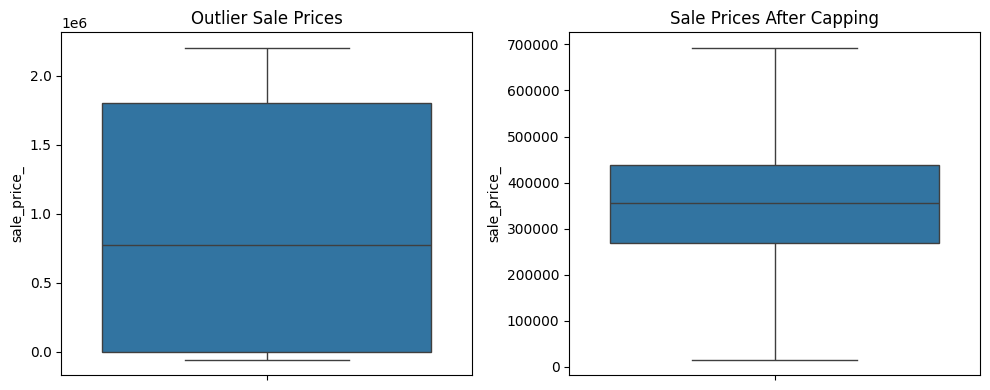

In [46]:
# Calculate IQR
Q1 = df['sale_price_'].quantile(0.25)
Q3 = df['sale_price_'].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Identify outliers
outliers = df[
    (df['sale_price_'] < lower) |
    (df['sale_price_'] > upper)
]

print("Number of outliers:", len(outliers))

# Handle outliers using capping
df['sale_price_'] = df['sale_price_'].clip(lower, upper)

# Visualize before and after handling
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
sns.boxplot(y=outliers['sale_price_'])
plt.title("Outlier Sale Prices")

plt.subplot(1, 2, 2)
sns.boxplot(y=df['sale_price_'])
plt.title("Sale Prices After Capping")

plt.tight_layout()
plt.show()

Number of outliers: 0


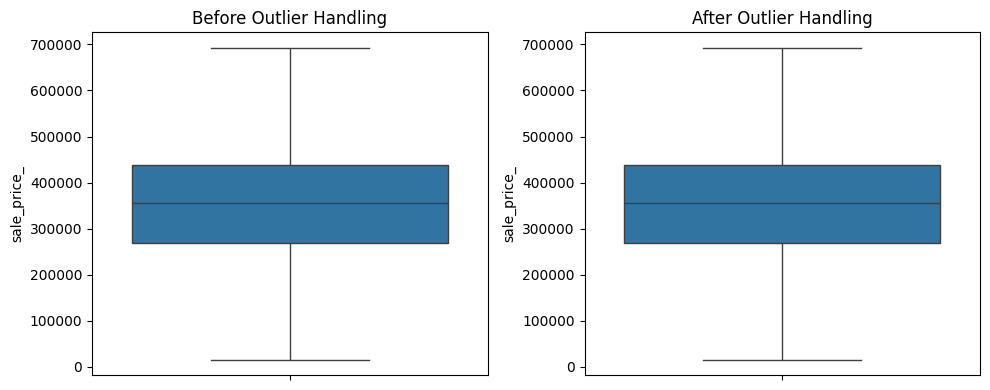

In [47]:
# Save original sale prices
original_prices = df['sale_price_'].copy()

# Calculate IQR
Q1 = df['sale_price_'].quantile(0.25)
Q3 = df['sale_price_'].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Identify outliers
outliers = df[(df['sale_price_'] < lower) | (df['sale_price_'] > upper)]

print("Number of outliers:", len(outliers))

# Handle outliers using capping
df['sale_price_'] = df['sale_price_'].clip(lower, upper)

# Compare before and after
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
sns.boxplot(y=original_prices)
plt.title("Before Outlier Handling")

plt.subplot(1, 2, 2)
sns.boxplot(y=df['sale_price_'])
plt.title("After Outlier Handling")

plt.tight_layout()
plt.show()